In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from spectrascope.SpectraScope import *
from spectrascope.features import * 
from sklearn.linear_model import Ridge, Lasso, ElasticNet
import SPA 

In [3]:
fnX = '../tests/test_files/X_testfile.npy'
fny = '../tests/test_files/y_testfile.npy'
X = np.load(fnX)
y = np.load(fny)

In [4]:
ss = SpectraScope(X = X, y = y, specnames=['pdf', 'xanes'], yname='nn')

no random seed selected, when splitting data, will always give different split
saving to /examples/models, change save_path kwarg if youd like to change


In [5]:
ss.add_x_axis(specname='xanes', value=np.linspace(4969.0, 5021.0, 200))
ss.add_x_axis(specname='pdf', value=np.linspace(0,10,200))

In [6]:
ss.add_spectral_feature('xanes', 'pointwise_features', xrange = ss.xanes_xaxis)
ss.add_spectral_feature('pdf', 'pointwise_features', xrange = ss.pdf_xaxis)

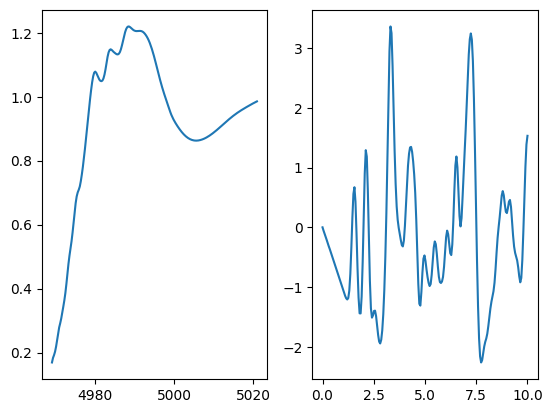

In [7]:
f, (ax1, ax2) = plt.subplots(1,2)
ax1.plot(ss.xanes_xaxis, ss.xanes_pointwise_features[0])
ax2.plot(ss.pdf_xaxis, ss.pdf_pointwise_features[0])

In [8]:
col = 'xanes'
spec = getattr(ss, f"{col}_pointwise_features")[0]
temp = spectral_features(ss.xanes_xaxis, spec)

(200,)


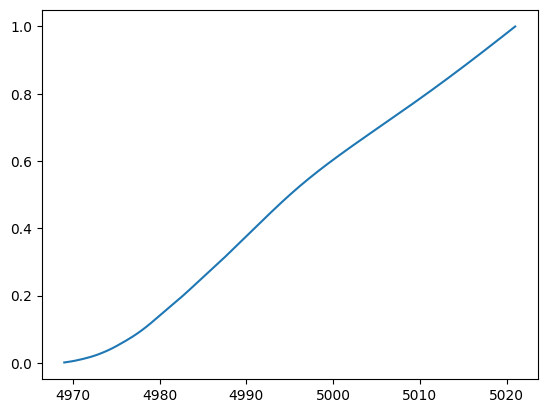

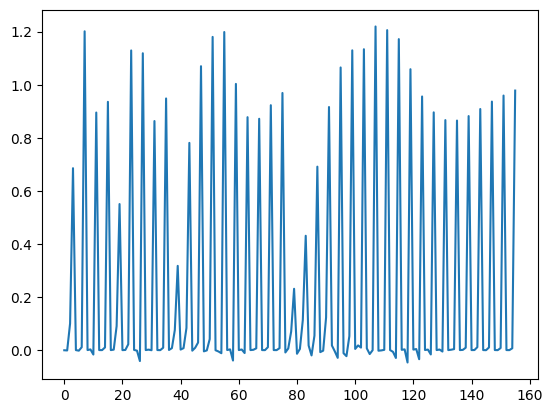

In [139]:
temp.__getattribute__('cdf').__call__()
x, y = temp.__getattribute__('plot_cdf').__call__()
plt.plot(x,y)

temp.__getattribute__('polynomial_featuresall').__call__()
x, y = temp.__getattribute__('plot_polynomial_featuresall').__call__()
plt.figure()
plt.plot(x,y)

In [9]:
from spectrascope.plot_spectral_features import * 

In [10]:
ss.add_spectral_feature('xanes', 'polynomial_featuresall')
ss.add_spectral_feature('xanes', 'polynomial_featuresN', N=5)
ss.add_spectral_feature('xanes', 'featureagg', n_clusters=10)
ss.add_spectral_feature('xanes', 'pca', n_components=10)
ss.add_spectral_feature('xanes', 'cdf')
ss.add_spectral_feature('xanes', 'cwt')

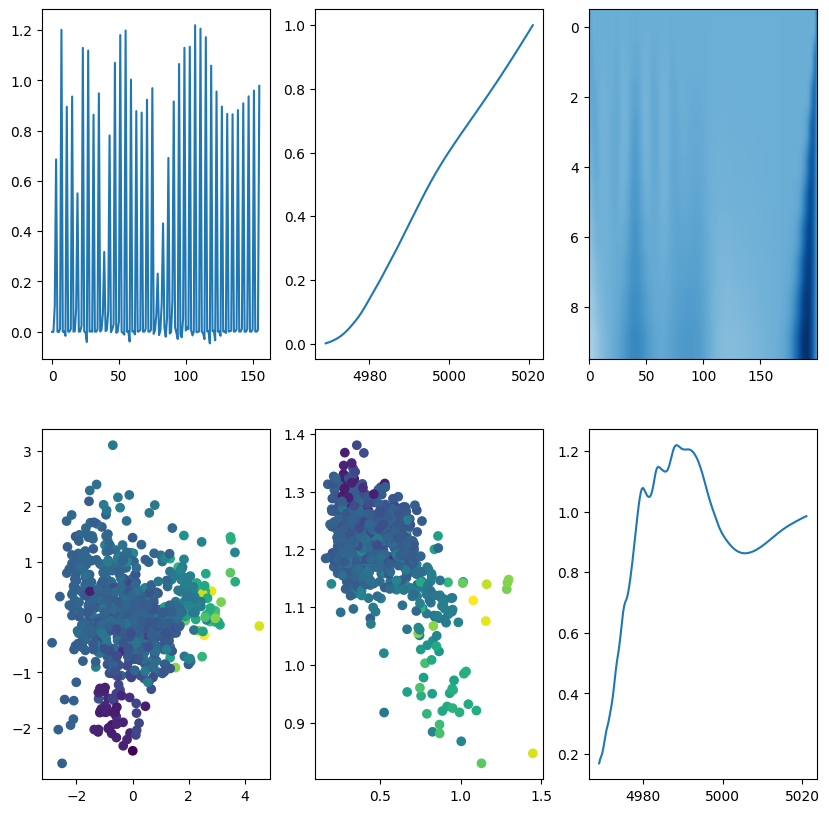

In [11]:
f, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2,3, figsize=(10,10))
ax1.plot(np.arange(156), ss.xanes_polynomial_featuresall[0][:-1])
ax2.plot(ss.xanes_xaxis, ss.xanes_cdf[0])

cwt_coefs = ss.xanes_cwt[0]
ax3.imshow(cwt_coefs.reshape(10,200), aspect='auto', cmap='Blues',
           vmax=(np.abs(cwt_coefs)).max(), vmin=-(np.abs(cwt_coefs)).max())

ax4.scatter(ss.xanes_pca[:,0], ss.xanes_pca[:,1], c = ss.nn)
ax5.scatter(ss.xanes_featureagg[:,0], ss.xanes_featureagg[:,1], c = ss.nn)

ax6.plot(ss.xanes_xaxis, ss.xanes[0])

In [10]:
ss.combine_feature('xanes_pointwise_features', 'pdf_pointwise_features')

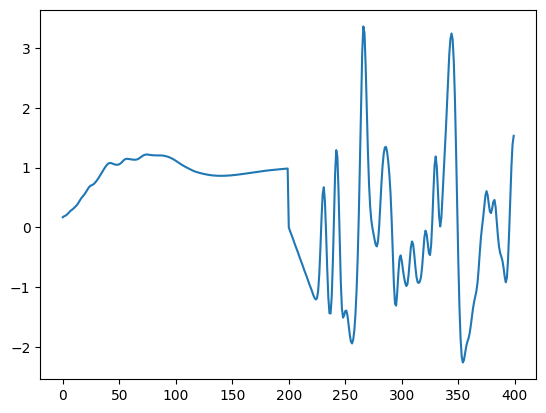

In [11]:
plt.plot(ss.xanes_pdf_pointwise_features[0])

In [26]:
ridge_kwargs = {'estimator':Ridge(), 
                             'param_grid': {'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                                           'fit_intercept':[True], 
                            }, 'refit':True, 
                             'metric':mean_squared_error}
                             
                             
lasso_kwargs = {'estimator':Lasso(), 
                'param_grid':{'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                            'fit_intercept':[True]
                    },
                'refit':True,
                'metric':mean_squared_error}

en_kwargs = {'estimator':ElasticNet(), 
                'param_grid':{'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                            'l1_ratio': [0.1, 0.5, 0.9],
                            'fit_intercept':[True]
                            },
                'refit':True,
                'metric':mean_squared_error}

RF_kwargs = {'estimator':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[50,100,200, 300], 
                                        'criterion':['squared_error'],
                                        'max_depth': [10,35, None]},
                'refit':True,
                'metric':mean_squared_error}

RF_kwargs = {'estimator':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[300], 
                                        'criterion':['squared_error'],
                                        'max_depth': [50, None]},
                'refit':True,
                'metric':mean_squared_error}

lcen_kwargs = {'l1_ratio':[0.01,0.1, 0.3, 0.5, 0.6, 0.99],
               'K_fold':5, 
               'cv_method':'Kfold', 
               'alpha':5, 
               'degree':[1],
               'trans_type':'poly', 
               'LCEN_cutoff':5e-2, 
               'LCEN_interaction':True, 
               'scale_X':True, 
               'scale_y':True}

In [16]:
ss.transform_feature('xanes_pointwise_features', degree=2, interaction=False)

In [19]:
ss.do_LCEN('xanes_pointwise_features', 'nn', 0.25, **lcen_kwargs)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
=== Residual Analysis ===
RMSE = 0.07883664373391693
APE = 2.4067454689856915
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.


In [27]:
ss.transform_feature('xanes_pointwise_features', degree=2, interaction=False)
# adding transformation separately 
# be careful with doing everything at once right now because if calling LCEN with trans
# on transformed features, will transform twice. You know what I mean? 

feats = {'pointwise_features':[{'specname':'xanes', 'xrange':ss.xanes_xaxis},
                               {'specname':'pdf', 'xrange':ss.pdf_xaxis}],
         'polynomial_featuresall':[
             { 'specname':'xanes', 'Narr':np.array([4,5,10,20]), 'degree':3},
             { 'specname':'pdf', 'Narr':np.array([4,5,10,20]), 'degree':3}], 
        'cdf': [{ 'specname':'xanes'}],
        'pointwise_features_trans' : [{'specname':'xanes'}]
         }
sk_kwargs = [lasso_kwargs, ridge_kwargs] #, en_kwargs]#, RF_kwargs]
multi_modal = [('xanes_pointwise_features', 'pdf_pointwise_features')] #, 
            #    ('xanes_polynomial_featuresall', 'pdf_polynomial_featuresall')]
ss.random_seed = 12
ss.do_all(feats, 'nn', 0.25, sk_kwargs=sk_kwargs, lcen_kwargs=lcen_kwargs, 
                multi_modal=multi_modal)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
=== Residual Analysis ===
RMSE = 0.038036450000158865
APE = 1.318310046671826
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
=== Residual Analysis ===
RMSE = 0.056558762784571795
APE = 2.056765965689431
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
=== Residual Analysis ===
RMSE = 0.03801796489165884
APE = 1.3284511528075262
The best model is LCEN. View

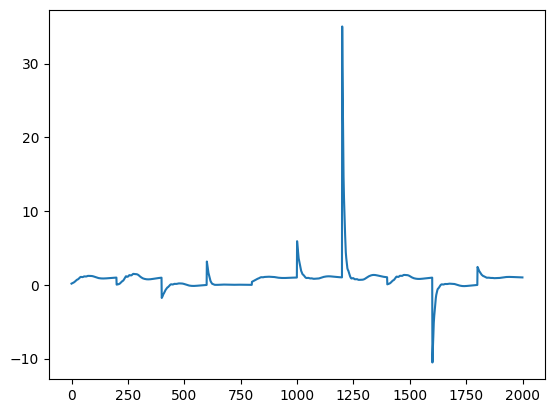

In [20]:
plt.plot(ss.xanes_pointwise_features_trans[0])

In [23]:
import seaborn as sns

<Axes: >

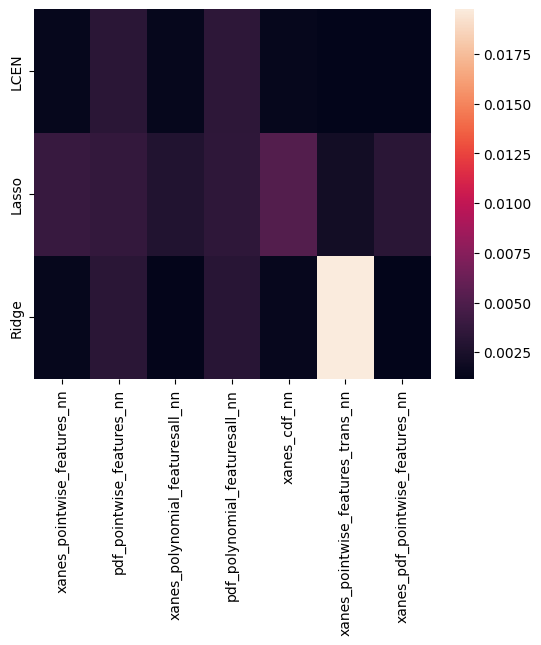

In [28]:
sns.heatmap(pd.DataFrame(ss.best_fits).T)